# DFT bands: PBE+U vs LDA+U, both materials

Side by side, each material's DFT bands from LDA+U (production) and PBE+U on the **same k path** (the PBE inputs copy
the LDA `bands.in` K_POINTS block and nbnd; `archive/setup_templates/MnBi2Te4/base/setup_dft_bands_pbe.sh`).
Same cell, positions, U and projectors; only the functional and the PAW datasets (`rel-pz` vs `rel-pbe`) differ.
Each functional's energies are relative to its own valence-band maximum on the path (band `nelec` counted from
the bottom, noncollinear: one electron per band).

* **MnBi₂Te₄** PBE+U: the bug #18 test D state (209052; atomic start, symmetric, |m|abs 10.17 μB, conv_thr 1e-7,
  with D3, which does not change the bands at fixed geometry). Noncollinear PBE's lower layer-asymmetric state is
  *not* this one; test D is the physical (R_I-3c) state. LDA+U: 214640 from SCF 214290 (1e-10).
* **Y₂Ir₂O₇** PBE+U: YP (210525, conv_thr 1e-7). LDA+U: 214641 from SCF 213998 (1e-10).


In [17]:
# ---- settings
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("/Users/treycole/Repos/axion-phonon")
DATA = ROOT / "data"
sys.path.insert(0, str(ROOT))
from axion_phonon.io.qe import read_bands_out, read_kpath

In [ ]:
PANELS = [   # (title, {functional: bands.out}, bands.in of the path, energy range rel. VBM)
    (r"(a) Y$_2$Ir$_2$O$_7$", {"LDA+U": DATA / "Y2Ir2O7/base/lda/dft_bands_214641/Y2Ir2O7.bands.out",
                               "PBE+U": DATA / "Y2Ir2O7/base/pbe/dft_bands_pbe_215099/Y2Ir2O7.bands.out"},
     DATA / "Y2Ir2O7/base/lda/dft_bands_214641/Y2Ir2O7.bands.in", (-20.0, 10.0)),
    (r"(b) MnBi$_2$Te$_4$", {"LDA+U": DATA / "MnBi2Te4/dft/base/bands/out/MnBi2Te4.bands.out",
                             "PBE+U": DATA / "MnBi2Te4/archive/base/pbe/dft_bands_pbe_215098/MnBi2Te4.bands.out"},
     DATA / "MnBi2Te4/dft/base/bands/out/MnBi2Te4.bands.in", (-15.0, 10.0)),
]
STYLES = {"LDA+U": {"color": "black", "lw": 0.8}, "PBE+U": {"color": "C3", "lw": 0.8, "ls": (0, (3, 2))}}
LABELS = {"G": r"$\Gamma$", "T": "Z", "P1": r"P$_1$"}   # path node names in bands.in -> figure
FIGSIZE = (7.0, 3.8)
CLOSE = 0.04                                            # ticks closer than this fraction of the path: labels pushed apart
FONT_SIZE = 8
SAVE_FIG = DATA / "pbe_vs_lda_bands.png"                # or None
# ---------------


In [ ]:
# ---- read; align each functional to its own VBM on the path
def nelec(out):
    """
    Read the number of electrons from a QE bands.out file.
    """
    return round(float(re.search(r"number of electrons\s*=\s*(\S+)", Path(out).read_text()).group(1)))

panels = []
for title, outs, bands_in, erange in PANELS:
    points, ticks = read_kpath(bands_in)
    lines = bands_in.read_text().splitlines()
    c = next(i for i, line in enumerate(lines) if line.strip().upper().startswith("CELL_PARAMETERS"))
    lattice = np.array([[float(v) for v in lines[c + j].split()[:3]] for j in (1, 2, 3)])
    recip = 2 * np.pi * np.linalg.inv(lattice).T
    x = np.r_[0, np.cumsum(np.linalg.norm(np.diff(points @ recip, axis=0), axis=1))]
    bands = {}
    for func, out in outs.items():
        if not Path(out).exists():
            print(f"{title} {func}: {out} not there yet"); continue
        _, e = read_bands_out(out)                         # (nbands, nk) eV
        assert e.shape[1] == len(points), (func, e.shape, len(points))
        n = nelec(out)
        vbm, cbm = e[n - 1].max(), e[n].min()
        direct = e[n] - e[n - 1]
        bands[func] = e - vbm
        names = {i: lab for i, lab in ticks}
        at = {names[i]: direct[i] for i in names if names[i] in ("G", "T", "L", "F")}
        print(f"{title} {func}: nelec {n}, indirect gap {1e3 * (cbm - vbm):.0f} meV "
              f"(VBM k {e[n - 1].argmax()}, CBM k {e[n].argmin()}), min direct {1e3 * direct.min():.0f} meV at k {direct.argmin()}; "
              + ", ".join(f"direct at {k} {1e3 * v:.0f} meV" for k, v in at.items()))
    panels.append((title, x, ticks, bands, erange))


(a) Y$_2$Ir$_2$O$_7$ LDA+U: nelec 164, indirect gap 685 meV (VBM k 136, CBM k 0), min direct 955 meV at k 131; direct at L 963 meV
(a) Y$_2$Ir$_2$O$_7$ PBE+U: nelec 164, indirect gap 774 meV (VBM k 136, CBM k 0), min direct 1054 meV at k 130; direct at L 1070 meV
(b) MnBi$_2$Te$_4$ LDA+U: nelec 138, indirect gap 163 meV (VBM k 77, CBM k 10), min direct 195 meV at k 11; direct at T 198 meV, direct at F 1044 meV, direct at L 979 meV
(b) MnBi$_2$Te$_4$ PBE+U: nelec 138, indirect gap 165 meV (VBM k 11, CBM k 10), min direct 167 meV at k 10; direct at T 167 meV, direct at F 1116 meV, direct at L 1046 meV


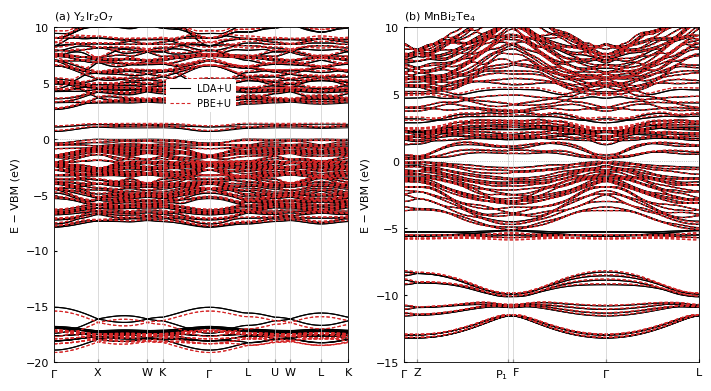

In [16]:
# ---- draw
plt.rcParams.update({"font.size": FONT_SIZE, "axes.linewidth": 0.6})
fig, axes = plt.subplots(1, len(panels), figsize=FIGSIZE, layout="constrained")
for ax, (title, x, ticks, bands, (lo, hi)) in zip(axes, panels):
    for func, e in bands.items():
        ax.plot(x, e.T, **STYLES[func])
        ax.plot([], [], label=func, **STYLES[func])
    for i, _ in ticks:
        ax.axvline(x[i], color="0.8", lw=0.5)
    ax.axhline(0, color="0.6", lw=0.5, ls=":")
    ax.set_xticks([x[i] for i, _ in ticks], [LABELS.get(l, l) for _, l in ticks])
    xt = [x[i] for i, _ in ticks]
    for j, lab in enumerate(ax.get_xticklabels()[1:-1], 1):   # the end labels sit on the axis edges
        if xt[j + 1] - xt[j] < CLOSE * x[-1]:
            lab.set_ha("right")
        elif xt[j] - xt[j - 1] < CLOSE * x[-1]:
            lab.set_ha("left")
    ax.set(xlim=(x[0], x[-1]), ylim=(lo, hi), ylabel="E − VBM (eV)")
    ax.set_title(title, loc="left", fontsize=FONT_SIZE)
    ax.tick_params(direction="in", length=2)
axes[0].legend(fontsize=FONT_SIZE - 1, loc="upper center", bbox_to_anchor=(0.5, 0.86), framealpha=1, edgecolor="none")   # in the YIO gap
if SAVE_FIG:
    fig.savefig(SAVE_FIG, dpi=250)
plt.show()
plt.rcdefaults()
